# ESMFold2 — CAMEO difficulty, length and resolution

Calculate how structure-prediction accuracy changes across this input regime, using the CAMEO protein panel and per-target ESMFold2 measurements.


## 1. Data source/acquisition

Download the fixed CAMEO FASTA, metadata, experimental structures and A3M alignments. Verify every file fingerprint. The public evaluation package supplies individual ESMFold2 scores and extended-chain reference scores.


In [1]:
from pathlib import Path, PurePosixPath
from types import SimpleNamespace
from concurrent.futures import ThreadPoolExecutor
import hashlib, io, json, os, sys, tempfile, urllib.request, zipfile
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib
matplotlib.use('Agg')
from matplotlib import pyplot as plt
from IPython.display import display, Image, Markdown
os.environ['OMP_NUM_THREADS']='2'
os.environ['MKL_NUM_THREADS']='2'
DATA_ROOT = Path(os.environ.get('ESMFOLD_DATA_ROOT', str(Path.cwd() / 'data-package'))).resolve()
CALC_ROOT = Path(os.environ.get('ESMFOLD_CALC_ROOT', str(Path.cwd() / 'calculations'))).resolve()
DATA_ROOT.mkdir(parents=True,exist_ok=True)
CALC_ROOT.mkdir(parents=True,exist_ok=True)


AXIS_NUMBER=2
PUBLIC_SOURCE='https://raw.githubusercontent.com/shreyjain11/SPECTRAagent/a3b7272548095e7f3df2dabe048c953d0b6316dd/reproduction/primary/esmfold2/'
SOURCE_FILES=[{'name': 'artifact_manifest.json', 'sha256': '99f77927255376a1da31cb38e1c8d6f09f6d9583dd5af12efcff4744cac5daaf'}, {'name': 'ACQUISITION_MANIFEST.json', 'sha256': 'edb706c2d48ef6655fe40b5f93a8a0f9e74cbe5045f12ebcdbe5784b95b23c10'}, {'name': 'ORIGINAL_ACQUISITION_EVIDENCE.json', 'sha256': '91817fe1b76b8d0d31f004d7f098033850d381737c1c167612d59415f17a7d4a'}]


In [2]:
def sha256_file(path):
    digest=hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda:stream.read(8*1024*1024),b''):digest.update(block)
    return digest.hexdigest()

def fetch_checked(url,destination,expected):
    destination=Path(destination)
    destination.parent.mkdir(parents=True,exist_ok=True)
    if not destination.is_file():
        temporary=destination.with_suffix(destination.suffix+'.part')
        with urllib.request.urlopen(url,timeout=120) as response,temporary.open('wb') as output:
            while True:
                block=response.read(1024*1024)
                if not block:break
                output.write(block)
        if sha256_file(temporary)!=expected:raise ValueError('Downloaded bytes failed SHA-256 verification: '+url)
        temporary.replace(destination)
    if sha256_file(destination)!=expected:raise ValueError('Cached bytes failed SHA-256 verification: '+str(destination))
    return destination

for item in SOURCE_FILES:
    fetch_checked(PUBLIC_SOURCE+item['name'],DATA_ROOT/item['name'],item['sha256'])
package=json.loads((DATA_ROOT/'artifact_manifest.json').read_text())
archive=fetch_checked(PUBLIC_SOURCE+package['archive'],DATA_ROOT/package['archive'],package['archive_sha256'])
with zipfile.ZipFile(archive) as bundle:
    for item in package['files']:
        relative=PurePosixPath(item['path'])
        if relative.is_absolute() or '..' in relative.parts:raise ValueError('Invalid input path')
        # Only data files are used; all custom Python is written in cells below.
        if relative.suffix in {'.py','.ipynb'}:continue
        destination=DATA_ROOT.joinpath(*relative.parts)
        if not destination.is_file():
            data=bundle.read('sha256/'+item['sha256'])
            if hashlib.sha256(data).hexdigest()!=item['sha256']:raise ValueError('Invalid input object')
            destination.parent.mkdir(parents=True,exist_ok=True)
            destination.write_bytes(data)
        if sha256_file(destination)!=item['sha256']:raise ValueError('Changed input data: '+str(relative))
print('Source data package verified:',package['archive_sha256'])


Source data package verified: e1afd7e920537a6ba5a1a716d715f6d1962f635e5274d3b8a5081e1903ed182f


In [3]:
ACQUISITION=json.loads((DATA_ROOT/'ACQUISITION_MANIFEST.json').read_text())
EVIDENCE=json.loads((DATA_ROOT/'ORIGINAL_ACQUISITION_EVIDENCE.json').read_text())
CAMEO_DIR=CALC_ROOT/'downloads/cameo'
CAMEO_DIR.mkdir(parents=True,exist_ok=True)
CACHE_DIR=Path(os.environ.get('ESMFOLD_CAMEO_CACHE',str(CAMEO_DIR)))
def matches_source(path,item):
    if not path.is_file():return False
    if len(item['etag'])==64:return sha256_file(path)==item['etag']
    data=path.read_bytes()
    return hashlib.sha1(('blob '+str(len(data))+'\0').encode()+data).hexdigest()==item['etag']
def get_cameo_source(item):
    relative=item['file'];destination=CAMEO_DIR/relative
    source_url='https://huggingface.co/datasets/'+ACQUISITION['pins']['cameo_repo']+'/resolve/'+ACQUISITION['pins']['cameo_revision']+'/'+relative
    if not matches_source(destination,item):
        candidate=CACHE_DIR/relative
        destination.parent.mkdir(parents=True,exist_ok=True)
        if candidate!=destination and matches_source(candidate,item):
            import shutil
            shutil.copyfile(candidate,destination)
        else:
            with urllib.request.urlopen(source_url,timeout=120) as response,destination.open('wb') as stream:
                while True:
                    block=response.read(1024*1024)
                    if not block:break
                    stream.write(block)
    if not matches_source(destination,item):raise ValueError('Source content fingerprint differs: '+relative)
    return {'file':relative,'url':source_url,'sha256':sha256_file(destination),'bytes':destination.stat().st_size}
source_items=[r for r in EVIDENCE['hf_download_metadata'] if r['file'] in ['meta.csv','sequences.fasta'] or r['file'].startswith(('msa/','experiment_structures/'))]
with ThreadPoolExecutor(max_workers=2) as pool:raw_sources=list(pool.map(get_cameo_source,source_items))
display(pd.DataFrame(raw_sources)[['file','url','bytes']])


,file,url,bytes
0,experiment_structures/8PIR_A.pdb,https://huggingface.co/datasets/THU-ATOM/cameo...,264796
1,experiment_structures/8PNS_A.pdb,https://huggingface.co/datasets/THU-ATOM/cameo...,370582
2,experiment_structures/8PVW_A.pdb,https://huggingface.co/datasets/THU-ATOM/cameo...,116566
3,experiment_structures/8Q83_A.pdb,https://huggingface.co/datasets/THU-ATOM/cameo...,217087
4,experiment_structures/8QCE_B.pdb,https://huggingface.co/datasets/THU-ATOM/cameo...,213766
...,...,...,...
279,msa/9MRB_A.a3m,https://huggingface.co/datasets/THU-ATOM/cameo...,330
280,msa/9MXW_B.a3m,https://huggingface.co/datasets/THU-ATOM/cameo...,217394
281,msa/9NSM_B.a3m,https://huggingface.co/datasets/THU-ATOM/cameo...,200687
282,msa/9NV5_B.a3m,https://huggingface.co/datasets/THU-ATOM/cameo...,1581474


## 2. Data processing

Parse sequences and experimental chains; remove A3M insertions before measuring alignment support. Reference eligibility requires at least30 C-alpha positions, no unknown query residues and query/reference identity of at least0.80. The model evaluation covers eligible sequences of at most650 residues.


In [4]:
import csv
import json
import math
import re
from collections import Counter, defaultdict
from pathlib import Path
import numpy as np
import pandas as pd
from Bio.PDB import PDBParser, PPBuilder
AA = set('ACDEFGHIKLMNPQRSTVWY')
THREE_TO_ONE = {'ALA': 'A', 'ARG': 'R', 'ASN': 'N', 'ASP': 'D', 'CYS': 'C', 'GLN': 'Q', 'GLU': 'E', 'GLY': 'G', 'HIS': 'H', 'ILE': 'I', 'LEU': 'L', 'LYS': 'K', 'MET': 'M', 'PHE': 'F', 'PRO': 'P', 'SER': 'S', 'THR': 'T', 'TRP': 'W', 'TYR': 'Y', 'VAL': 'V', 'SEC': 'U', 'PYL': 'O'}

def read_fasta(path: Path) -> dict[str, str]:
    records = {}
    name = None
    parts = []
    for line in path.read_text().splitlines():
        line = line.strip()
        if not line:
            continue
        if line.startswith('>'):
            if name is not None:
                records[name] = ''.join(parts)
            name = line[1:].split()[0]
            parts = []
        else:
            parts.append(line)
    if name is not None:
        records[name] = ''.join(parts)
    return records

def parse_ref(value: str) -> tuple[str, str, str]:
    m = re.match('\\s*([0-9A-Za-z]{4})\\s*\\[\\s*([A-Za-z0-9]+)\\s*\\]\\s*', value)
    if not m:
        raise ValueError(f'cannot parse ref PDB [Chain]: {value!r}')
    pdb = m.group(1).upper()
    chain = m.group(2)
    return (pdb, chain, f'{pdb}_{chain}')

def read_a3m(path: Path) -> list[tuple[str, str]]:
    rows = []
    name = None
    parts = []
    if not path.exists():
        return rows
    for line in path.read_text(errors='replace').splitlines():
        line = line.rstrip()
        if not line:
            continue
        if line.startswith('>'):
            if name is not None:
                rows.append((name, ''.join(parts)))
            name = line[1:]
            parts = []
        else:
            parts.append(line)
    if name is not None:
        rows.append((name, ''.join(parts)))
    return rows

def strip_a3m_insertions(seq: str) -> str:
    return ''.join((c for c in seq if not c.islower()))

def msa_features(path: Path, query: str) -> dict[str, float]:
    rows = read_a3m(path)
    if not rows:
        return {'msa_rows': 0, 'msa_nonquery_rows': 0, 'msa_log10_nonquery_rows': 0.0, 'msa_top_nonquery_identity': np.nan, 'msa_median_identity': np.nan, 'msa_q90_identity': np.nan, 'msa_frac_id_ge_0_9': np.nan, 'msa_frac_id_ge_0_7': np.nan, 'msa_frac_cov_ge_0_7': np.nan}
    q = strip_a3m_insertions(rows[0][1]).replace('-', '')
    if not q:
        q = query
    identities = []
    coverages = []
    for _name, raw in rows[1:]:
        aligned = strip_a3m_insertions(raw)
        matches = 0
        aligned_non_gap = 0
        for i, qc in enumerate(q):
            rc = aligned[i] if i < len(aligned) else '-'
            if rc != '-':
                aligned_non_gap += 1
                if rc == qc:
                    matches += 1
        cov = aligned_non_gap / max(1, len(q))
        ident = matches / max(1, aligned_non_gap)
        identities.append(ident)
        coverages.append(cov)
    ids = np.asarray(identities, dtype=float)
    covs = np.asarray(coverages, dtype=float)
    return {'msa_rows': len(rows), 'msa_nonquery_rows': max(0, len(rows) - 1), 'msa_log10_nonquery_rows': float(math.log10(max(0, len(rows) - 1) + 1)), 'msa_top_nonquery_identity': float(np.nanmax(ids)) if ids.size else np.nan, 'msa_median_identity': float(np.nanmedian(ids)) if ids.size else np.nan, 'msa_q90_identity': float(np.nanquantile(ids, 0.9)) if ids.size else np.nan, 'msa_frac_id_ge_0_9': float(np.nanmean(ids >= 0.9)) if ids.size else np.nan, 'msa_frac_id_ge_0_7': float(np.nanmean(ids >= 0.7)) if ids.size else np.nan, 'msa_frac_cov_ge_0_7': float(np.nanmean(covs >= 0.7)) if covs.size else np.nan}

def sequence_features(seq: str) -> dict[str, float]:
    clean = ''.join((c if c in AA else 'X' for c in seq))
    n = len(clean)
    counts = Counter(clean)
    probs = np.asarray([counts[a] / n for a in sorted(AA) if counts[a] > 0], dtype=float)
    entropy = -float(np.sum(probs * np.log2(probs))) if probs.size else 0.0
    hydrophobic = set('AILMFWYV')
    return {'seq_len': n, 'seq_entropy': entropy, 'seq_max_aa_fraction': max(counts.values()) / n if n else np.nan, 'seq_low_complexity_proxy': float(max(counts.values()) / n) if n else np.nan, 'seq_cys_fraction': counts['C'] / n if n else np.nan, 'seq_gly_pro_fraction': (counts['G'] + counts['P']) / n if n else np.nan, 'seq_hydrophobic_fraction': sum((counts[a] for a in hydrophobic)) / n if n else np.nan, 'seq_unknown_fraction': sum((counts[a] for a in set(clean) - AA)) / n if n else np.nan}

def pdb_chain_sequence_and_ca(path: Path, chain_id: str) -> tuple[str, int, int, str, str]:
    parser = PDBParser(QUIET=True)
    structure = parser.get_structure(path.stem, str(path))
    model = next(structure.get_models())
    actual_chain = chain_id
    chain_note = 'requested_chain'
    if chain_id not in model:
        chains = list(model)
        nonempty = [c for c in chains if sum((1 for r in c if 'CA' in r)) > 0]
        if len(nonempty) == 1:
            actual_chain = nonempty[0].id
            chain_note = 'single_chain_fallback'
        else:
            return ('', 0, 0, '', 'missing_requested_chain')
    seq = []
    ca = 0
    residues = 0
    for res in model[actual_chain]:
        hetflag, _resseq, _icode = res.id
        if hetflag.strip():
            continue
        one = THREE_TO_ONE.get(res.resname.upper(), 'X')
        seq.append(one)
        residues += 1
        if 'CA' in res:
            ca += 1
    return (''.join(seq), residues, ca, actual_chain, chain_note)

def global_identity(a: str, b: str) -> float:
    if not a or not b:
        return 0.0
    m = min(len(a), len(b))
    prefix_ident = sum((x == y for x, y in zip(a[:m], b[:m]))) / max(len(a), len(b))
    if prefix_ident > 0.98 and abs(len(a) - len(b)) <= 3:
        return float(prefix_ident)
    from Bio import pairwise2
    aln = pairwise2.align.globalms(a, b, 2, -1, -10, -0.5, one_alignment_only=True)[0]
    aa, bb = (aln.seqA, aln.seqB)
    both = [(x, y) for x, y in zip(aa, bb) if x != '-' and y != '-']
    if not both:
        return 0.0
    return sum((x == y for x, y in both)) / len(both)

def add_near_duplicate_groups(rows: list[dict]) -> None:
    seqs = [r['sequence'] for r in rows]
    n = len(seqs)
    parent = list(range(n))

    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x

    def union(a, b):
        ra, rb = (find(a), find(b))
        if ra != rb:
            parent[rb] = ra
    for i in range(n):
        for j in range(i + 1, n):
            if seqs[i] == seqs[j]:
                union(i, j)
                continue
            if abs(len(seqs[i]) - len(seqs[j])) > 0.1 * max(len(seqs[i]), len(seqs[j])):
                continue
            m = min(len(seqs[i]), len(seqs[j]))
            ident = sum((a == b for a, b in zip(seqs[i][:m], seqs[j][:m]))) / max(len(seqs[i]), len(seqs[j]))
            if ident >= 0.9:
                union(i, j)
    group_map = {}
    next_group = 0
    counts = defaultdict(int)
    for i in range(n):
        r = find(i)
        if r not in group_map:
            group_map[r] = next_group
            next_group += 1
        rows[i]['seq_cluster90_proxy'] = group_map[r]
        counts[group_map[r]] += 1
    for r in rows:
        r['seq_cluster90_proxy_size'] = counts[r['seq_cluster90_proxy']]


In [5]:
fasta=read_fasta(CAMEO_DIR/'sequences.fasta')
metadata=pd.read_csv(CAMEO_DIR/'meta.csv')
rows=[]
for _,record in metadata.iterrows():
    pdb_id,chain_id,target_id=parse_ref(record['ref. PDB [Chain]'])
    sequence=fasta[target_id]
    reference_path=CAMEO_DIR/'experiment_structures'/f'{target_id}.pdb'
    alignment_path=CAMEO_DIR/'msa'/f'{target_id}.a3m'
    ref_sequence,residues,ca_count,actual_chain,chain_note=pdb_chain_sequence_and_ca(reference_path,chain_id)
    row={'target_id':target_id,'sequence':sequence,'submission_date':str(record['Submission Date'])[:10],
         'difficulty':int(record['Difficulty']),'resolution':float(record['Resolution']) if pd.notna(record['Resolution']) else np.nan,
         'method':record['Method'],'ref_chain':actual_chain,'pdb_path':str(reference_path),'msa_path':str(alignment_path),
         'ref_ca_residues':ca_count,'query_ref_identity':global_identity(sequence,ref_sequence)}
    row.update(sequence_features(sequence));row.update(msa_features(alignment_path,sequence))
    row['eligible_reference']=ca_count>=30 and row['seq_unknown_fraction']==0 and row['query_ref_identity']>=.80
    rows.append(row)
add_near_duplicate_groups(rows)
features=pd.DataFrame(rows).sort_values(['submission_date','target_id']).reset_index(drop=True)
analysis_features=features[features.eligible_reference & features.seq_len.le(650)].copy()
print('Source targets:',len(features),'eligible for evaluation:',len(analysis_features))
display(features[['target_id','seq_len','msa_nonquery_rows','difficulty','resolution','ref_ca_residues','query_ref_identity','eligible_reference']])


/ewsc/yektefai/spectra_runs/all_axes_inline_20261109/esmfold2/.venv/lib/python3.11/site-packages/Bio/pairwise2.py:278: BiopythonDeprecationWarning: Bio.pairwise2 has been deprecated, and we intend to remove it in a future release of Biopython. As an alternative, please consider using Bio.Align.PairwiseAligner as a replacement, and contact the Biopython developers if you still need the Bio.pairwise2 module.
  warnings.warn(


Source targets: 141 eligible for evaluation: 138


,target_id,seq_len,msa_nonquery_rows,difficulty,resolution,ref_ca_residues,query_ref_identity,eligible_reference
0,8PIR_A,473,4977,0,2.70,440,1.0,True
1,8PNS_A,603,4776,0,2.08,600,1.0,True
2,8XOQ_A,250,4843,1,2.41,239,1.0,True
3,8XPI_A,107,586,0,1.84,90,1.0,True
4,8XTN_A,33,3,2,0.00,33,1.0,True
...,...,...,...,...,...,...,...,...
136,9FW6_A,361,4561,0,1.73,338,1.0,True
137,9G58_A,159,4539,1,2.40,131,1.0,True
138,9G59_B,152,4920,1,2.40,141,1.0,True
139,9KGB_A,377,46,1,1.76,336,1.0,True


## 3. Axis definition and level construction

Evolutionary support is log10(non-query alignment rows+1). Increasing stress levels correspond to decreasing support. Construct5 and8 equal-count ranked bins and the thresholds ≥3.0,2.6–3.0 and<2.6. CAMEO difficulty uses the supplied ordered category; length uses5 increasing bins. The calibration population is fixed by input/reference eligibility before performance is joined.


In [6]:
import json
from datetime import datetime
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

def qbin(df, col, n, reverse=True):
    ranks = df[col].rank(method='first')
    bins = pd.qcut(ranks, q=n, labels=False, duplicates='drop')
    return (bins.max() - bins if reverse else bins).astype(int)

def add_axis(df):
    df = df.copy()
    df['msa_depth_q5_level'] = qbin(df, 'msa_log10_nonquery_rows', 5, True)
    df['msa_depth_q8_level'] = qbin(df, 'msa_log10_nonquery_rows', 8, True)
    df['low_msa_threshold_level'] = np.select([df['msa_log10_nonquery_rows'] >= 3.0, df['msa_log10_nonquery_rows'] >= 2.6], [0, 1], default=2)
    df['cameo_ease_similarity'] = 2 - df['difficulty']
    df['cameo_difficulty_level'] = df['difficulty'].astype(int)
    df['length_q5_level'] = qbin(df, 'seq_len', 5, False)
    return df
axis_features=add_axis(analysis_features)
axis_features['low_msa_lt3']=(axis_features.msa_log10_nonquery_rows<3).astype(int)
axis_features['very_low_msa_lt2_6']=(axis_features.msa_log10_nonquery_rows<2.6).astype(int)
display(axis_features[['target_id','msa_log10_nonquery_rows','msa_depth_q5_level','msa_depth_q8_level','low_msa_threshold_level','cameo_difficulty_level','length_q5_level']])


,target_id,msa_log10_nonquery_rows,msa_depth_q5_level,msa_depth_q8_level,low_msa_threshold_level,cameo_difficulty_level,length_q5_level
0,8PIR_A,3.697055,0,0,0,0,4
1,8PNS_A,3.679155,1,1,0,0,4
2,8XOQ_A,3.685204,0,1,0,1,2
3,8XPI_A,2.768638,4,6,1,0,0
4,8XTN_A,0.602060,4,7,2,2,0
...,...,...,...,...,...,...,...
136,9FW6_A,3.659155,2,3,0,0,3
137,9G58_A,3.657056,2,3,0,1,1
138,9G59_B,3.692053,0,0,0,1,1
139,9KGB_A,1.672098,4,7,2,1,3


## 4. Model results or released scores

Use the package’s per-target ESMFold2 measurements:3 loops,14 diffusion steps and1 sample, with the query sequence as model input. The A3M alignment is an axis attribute; it is not supplied to the model. The visible functions below also define model-output coordinate extraction, alignment and scoring for an available compatible checkpoint.


In [7]:
model_scoring = SimpleNamespace(__file__=str(DATA_ROOT / 'model_scoring.py'))
model_scoring.torch = None
import argparse as model_scoring__import_argparse
model_scoring.argparse = model_scoring__import_argparse
import gc as model_scoring__import_gc
model_scoring.gc = model_scoring__import_gc
import json as model_scoring__import_json
model_scoring.json = model_scoring__import_json
import math as model_scoring__import_math
model_scoring.math = model_scoring__import_math
import os as model_scoring__import_os
model_scoring.os = model_scoring__import_os
import time as model_scoring__import_time
model_scoring.time = model_scoring__import_time
from pathlib import Path as model_scoring__import_Path
model_scoring.Path = model_scoring__import_Path
import numpy as model_scoring__import_np
model_scoring.np = model_scoring__import_np
import pandas as model_scoring__import_pd
model_scoring.pd = model_scoring__import_pd
from Bio import pairwise2 as model_scoring__import_pairwise2
model_scoring.pairwise2 = model_scoring__import_pairwise2
from Bio.PDB import PDBParser as model_scoring__import_PDBParser
model_scoring.PDBParser = model_scoring__import_PDBParser
from Bio.SVDSuperimposer import SVDSuperimposer as model_scoring__import_SVDSuperimposer
model_scoring.SVDSuperimposer = model_scoring__import_SVDSuperimposer
model_scoring.ROOT = model_scoring.Path(model_scoring.__file__).resolve().parents[1]
model_scoring.AA3 = {'ALA': 'A', 'ARG': 'R', 'ASN': 'N', 'ASP': 'D', 'CYS': 'C', 'GLN': 'Q', 'GLU': 'E', 'GLY': 'G', 'HIS': 'H', 'ILE': 'I', 'LEU': 'L', 'LYS': 'K', 'MET': 'M', 'PHE': 'F', 'PRO': 'P', 'SER': 'S', 'THR': 'T', 'TRP': 'W', 'TYR': 'Y', 'VAL': 'V', 'SEC': 'U', 'PYL': 'O'}
model_scoring.RESULT_COLUMNS = ['target_id', 'status', 'error', 'wall_sec', 'ptm', 'plddt_mean', 'plddt_ca_mean', 'alignment_identity', 'alignment_coverage', 'aligned_ca', 'ca_lddt', 'ca_rmsd', 'gdt_ts', 'ca_median_error', 'ca_p90_error', 'baseline_ca_lddt', 'baseline_gdt_ts', 'baseline_ca_rmsd']

def model_scoring__configure_torch() -> None:
    model_scoring.os.environ.setdefault('TORCH_CUDNN_SDPA_ENABLED', '0')
    try:
        model_scoring.torch.backends.cuda.enable_cudnn_sdp(False)
        model_scoring.torch.backends.cuda.enable_flash_sdp(False)
        model_scoring.torch.backends.cuda.enable_mem_efficient_sdp(False)
        model_scoring.torch.backends.cuda.enable_math_sdp(True)
    except Exception:
        pass
model_scoring.configure_torch = model_scoring__configure_torch

def model_scoring__ref_ca(path: model_scoring.Path, chain_id: str) -> tuple[str, model_scoring.np.ndarray]:
    parser = model_scoring.PDBParser(QUIET=True)
    structure = parser.get_structure(path.stem, str(path))
    model = next(structure.get_models())
    seq = []
    coords = []
    actual_chain = chain_id
    if actual_chain not in model:
        chains = list(model)
        nonempty = [c for c in chains if sum((1 for r in c if 'CA' in r)) > 0]
        if len(nonempty) == 1:
            actual_chain = nonempty[0].id
    for res in model[actual_chain]:
        hetflag, _resseq, _icode = res.id
        if hetflag.strip() or 'CA' not in res:
            continue
        seq.append(model_scoring.AA3.get(res.resname.upper(), 'X'))
        coords.append(res['CA'].get_coord().astype(model_scoring.np.float32))
    return (''.join(seq), model_scoring.np.asarray(coords, dtype=model_scoring.np.float32))
model_scoring.ref_ca = model_scoring__ref_ca

def model_scoring__pred_ca_from_output(output: dict) -> model_scoring.np.ndarray:
    coords = output['sample_atom_coords']
    if coords.dim() == 4:
        coords = coords[:, 0]
    coords = coords.detach().float().cpu().numpy()[0]
    atom_to_token = output['atom_to_token'].detach().cpu().numpy()
    ref_chars = output['ref_atom_name_chars'].detach().cpu().numpy()
    atom_mask = output['atom_attention_mask'].detach().cpu().numpy().astype(bool)
    token_mask = output['token_attention_mask'].detach().cpu().numpy().astype(bool)
    if atom_to_token.ndim == 2:
        atom_to_token = atom_to_token[0]
        ref_chars = ref_chars[0]
        atom_mask = atom_mask[0]
        token_mask = token_mask[0]
    n = int(token_mask.sum())
    out = model_scoring.np.full((n, 3), model_scoring.np.nan, dtype=model_scoring.np.float32)
    for i in range(atom_to_token.shape[0]):
        if not atom_mask[i]:
            continue
        name = ''.join((chr(int(c) + 32) if int(c) != 0 else ' ' for c in ref_chars[i])).strip()
        if name == 'CA':
            tok = int(atom_to_token[i])
            if 0 <= tok < n:
                out[tok] = coords[i]
    return out
model_scoring.pred_ca_from_output = model_scoring__pred_ca_from_output

def model_scoring__alignment_pairs(query: str, ref: str) -> tuple[list[tuple[int, int]], float, float]:
    aln = model_scoring.pairwise2.align.globalms(query, ref, 2, -1, -10, -0.5, one_alignment_only=True)[0]
    qi = ri = 0
    pairs = []
    matches = 0
    both = 0
    for a, b in zip(aln.seqA, aln.seqB):
        qpos = qi if a != '-' else None
        rpos = ri if b != '-' else None
        if a != '-':
            qi += 1
        if b != '-':
            ri += 1
        if qpos is not None and rpos is not None:
            pairs.append((qpos, rpos))
            both += 1
            matches += int(a == b)
    identity = matches / both if both else 0.0
    coverage = both / max(1, len(query))
    return (pairs, identity, coverage)
model_scoring.alignment_pairs = model_scoring__alignment_pairs

def model_scoring__kabsch_metrics(pred: model_scoring.np.ndarray, ref: model_scoring.np.ndarray) -> dict[str, float]:
    sup = model_scoring.SVDSuperimposer()
    sup.set(ref.astype(model_scoring.np.float64), pred.astype(model_scoring.np.float64))
    sup.run()
    pred_fit = sup.get_transformed()
    d = model_scoring.np.linalg.norm(pred_fit - ref, axis=1)
    return {'ca_rmsd': float(sup.get_rms()), 'gdt_ts': float(model_scoring.np.mean([model_scoring.np.mean(d < t) for t in (1.0, 2.0, 4.0, 8.0)])), 'ca_median_error': float(model_scoring.np.median(d)), 'ca_p90_error': float(model_scoring.np.quantile(d, 0.9))}
model_scoring.kabsch_metrics = model_scoring__kabsch_metrics

def model_scoring__ca_lddt(pred: model_scoring.np.ndarray, ref: model_scoring.np.ndarray, cutoff: float=15.0) -> float:
    n = len(ref)
    if n < 2:
        return float('nan')
    diff_ref = ref[:, None, :] - ref[None, :, :]
    diff_pred = pred[:, None, :] - pred[None, :, :]
    d_ref = model_scoring.np.linalg.norm(diff_ref, axis=-1)
    d_pred = model_scoring.np.linalg.norm(diff_pred, axis=-1)
    mask = model_scoring.np.triu((d_ref > 0) & (d_ref < cutoff), 1)
    if not model_scoring.np.any(mask):
        return float('nan')
    delta = model_scoring.np.abs(d_ref[mask] - d_pred[mask])
    return float(model_scoring.np.mean([(delta < t).mean() for t in (0.5, 1.0, 2.0, 4.0)]))
model_scoring.ca_lddt = model_scoring__ca_lddt

def model_scoring__extended_chain(n: int) -> model_scoring.np.ndarray:
    coords = model_scoring.np.zeros((n, 3), dtype=model_scoring.np.float32)
    coords[:, 0] = model_scoring.np.arange(n, dtype=model_scoring.np.float32) * 3.8
    return coords
model_scoring.extended_chain = model_scoring__extended_chain

def model_scoring__score_prediction(query: str, pred_ca: model_scoring.np.ndarray, ref_seq: str, ref_coords: model_scoring.np.ndarray) -> dict[str, float]:
    pairs, ident, cov = model_scoring.alignment_pairs(query, ref_seq)
    valid = [(q, r) for q, r in pairs if q < len(pred_ca) and r < len(ref_coords) and model_scoring.np.isfinite(pred_ca[q]).all()]
    if len(valid) < 30:
        return {'alignment_identity': ident, 'alignment_coverage': cov, 'aligned_ca': len(valid), 'ca_lddt': model_scoring.np.nan, 'gdt_ts': model_scoring.np.nan, 'ca_rmsd': model_scoring.np.nan, 'baseline_ca_lddt': model_scoring.np.nan, 'baseline_gdt_ts': model_scoring.np.nan, 'baseline_ca_rmsd': model_scoring.np.nan}
    qidx = model_scoring.np.asarray([q for q, _r in valid], dtype=int)
    ridx = model_scoring.np.asarray([r for _q, r in valid], dtype=int)
    pred = pred_ca[qidx]
    ref = ref_coords[ridx]
    metrics = {'alignment_identity': ident, 'alignment_coverage': cov, 'aligned_ca': len(valid), 'ca_lddt': model_scoring.ca_lddt(pred, ref)}
    metrics.update(model_scoring.kabsch_metrics(pred, ref))
    baseline = model_scoring.extended_chain(len(valid))
    metrics['baseline_ca_lddt'] = model_scoring.ca_lddt(baseline, ref)
    base_k = model_scoring.kabsch_metrics(baseline, ref)
    metrics['baseline_gdt_ts'] = base_k['gdt_ts']
    metrics['baseline_ca_rmsd'] = base_k['ca_rmsd']
    return metrics
model_scoring.score_prediction = model_scoring__score_prediction

def predict_and_score(sequence, reference_path, reference_chain, model_directory, loops=3, steps=14, samples=1, seed=0):
    import torch
    from transformers import EsmFold2Model
    from transformers.models.esmfold2.protein_utils import prepare_protein_features
    torch.set_num_threads(2)
    if not torch.cuda.is_available():
        raise RuntimeError('This inference function requires an available CUDA GPU')
    model_scoring.torch = torch
    model_scoring.configure_torch()
    model, loading = EsmFold2Model.from_pretrained(model_directory, output_loading_info=True)
    problems = {key: value for key, value in loading.items() if key in ['missing_keys', 'unexpected_keys', 'mismatched_keys', 'error_msgs', 'conversion_errors', 'skipped_pp_keys'] and value}
    if problems:
        raise RuntimeError('Incomplete model loading: ' + str(problems))
    model = model.cuda().eval()
    model.esmc.to(torch.bfloat16)
    torch.manual_seed(seed)
    features = prepare_protein_features(sequence, device=model.device)
    with torch.inference_mode():
        output = model.fold(**features, num_loops=loops, num_sampling_steps=steps, num_diffusion_samples=samples)
    values = dict(output)
    for key in ['atom_to_token', 'ref_atom_name_chars', 'atom_attention_mask']:
        values[key] = features[key]
    values['token_attention_mask'] = features['attention_mask']
    coordinates = model_scoring.pred_ca_from_output(values)
    reference_sequence, reference_coordinates = model_scoring.ref_ca(Path(reference_path), reference_chain)
    return model_scoring.score_prediction(sequence, coordinates, reference_sequence, reference_coordinates)


In [8]:
score_source=DATA_ROOT/'original_runs/esmfold2_single_controller_final_run/target_model_results.csv'
released_scores=pd.read_csv(score_source)
measurements=axis_features.merge(released_scores,on='target_id',validate='one_to_one')
measurements=measurements[measurements.status.eq('ok') & measurements.ca_lddt.notna()].copy()
if len(measurements)!=len(axis_features):raise RuntimeError('Evaluation population is incomplete; inspect explicit failed or missing target rows before fitting levels')
display(measurements[['target_id','ca_lddt','gdt_ts','ca_rmsd','baseline_ca_lddt','baseline_gdt_ts']])
print('Scored target chains:',len(measurements),'| loops3; diffusion steps14; samples1; sequence-only input')


,target_id,ca_lddt,gdt_ts,ca_rmsd,baseline_ca_lddt,baseline_gdt_ts
0,8PIR_A,0.950593,0.366477,9.769519,0.073709,0.000000
1,8PNS_A,0.982846,0.991667,0.507158,0.054734,0.001667
2,8XOQ_A,0.875434,0.711297,3.470126,0.068748,0.000000
3,8XPI_A,0.517151,0.375000,7.620268,0.078485,0.008333
4,8XTN_A,0.324627,0.106061,9.131442,0.183582,0.015152
...,...,...,...,...,...,...
133,9FW6_A,0.965189,0.962278,0.715727,0.060825,0.000000
134,9G58_A,0.888260,0.853053,1.602341,0.088345,0.005725
135,9G59_B,0.914110,0.723404,3.928177,0.091563,0.000000
136,9KGB_A,0.847124,0.776042,3.369703,0.053365,0.000000


Scored target chains: 138 | loops3; diffusion steps14; samples1; sequence-only input


## 5. Curves and controls

Calculate level means and95% target-resampling intervals. Compare the model with the extended-chain reference on the same targets. Inspect continuous rank associations and regressions adjusting for length, resolution, reference accuracy and CAMEO difficulty.


In [9]:
import json
from datetime import datetime
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

def spc_table(df, axis, level_col, similarity_col):
    rows = []
    for level, g in df.groupby(level_col):
        rows.append({'axis': axis, 'level': int(level), 'n': int(len(g)), 'similarity_mean': float(g[similarity_col].mean()), 'similarity_min': float(g[similarity_col].min()), 'similarity_max': float(g[similarity_col].max()), 'msa_log10_nonquery_mean': float(g['msa_log10_nonquery_rows'].mean()), 'difficulty_mean': float(g['difficulty'].mean()), 'seq_len_mean': float(g['seq_len'].mean()), 'resolution_mean': float(g['resolution'].mean()), 'target_ca_lddt_mean': float(g['ca_lddt'].mean()), 'target_ca_lddt_median': float(g['ca_lddt'].median()), 'target_gdt_ts_mean': float(g['gdt_ts'].mean()), 'target_ca_rmsd_median': float(g['ca_rmsd'].median()), 'baseline_ca_lddt_mean': float(g['baseline_ca_lddt'].mean()), 'baseline_gdt_ts_mean': float(g['baseline_gdt_ts'].mean()), 'status_ok_rate': float((g['status'] == 'ok').mean()), 'wall_sec_mean': float(g['wall_sec'].mean())})
    return pd.DataFrame(rows).sort_values('level')

def linear_control(df, xcols):
    X = df[xcols].fillna(0).to_numpy()
    y = df['ca_lddt'].to_numpy()
    model = LinearRegression().fit(X, y)
    pred = model.predict(X)
    return {'xcols': xcols, 'coef': {c: float(v) for c, v in zip(xcols, model.coef_)}, 'intercept': float(model.intercept_), 'r2': float(r2_score(y, pred))}
def curve_intervals(frame,level_column,reps=2000,seed=7):
    rng=np.random.default_rng(seed);out=[]
    for level,group in frame.groupby(level_column):
        row={'level':int(level),'n':len(group)}
        for metric in ['ca_lddt','baseline_ca_lddt']:
            values=group[metric].dropna().to_numpy(float)
            draws=np.array([rng.choice(values,len(values),replace=True).mean() for _ in range(reps)])
            row.update({metric+'_mean':float(values.mean()),metric+'_lo':float(np.quantile(draws,.025)),metric+'_hi':float(np.quantile(draws,.975))})
        out.append(row)
    return pd.DataFrame(out).sort_values('level')
def plot_curve(table,title):
    fig,ax=plt.subplots(figsize=(7,4),layout='constrained')
    for metric,label,color in [('ca_lddt','ESMFold2','#176B9A'),('baseline_ca_lddt','Extended-chain reference','#B26436')]:
        mean=table[metric+'_mean'];lo=table[metric+'_lo'];hi=table[metric+'_hi']
        ax.errorbar(table.level,mean,yerr=[mean-lo,hi-mean],marker='o',capsize=3,label=label,color=color)
    ax.set(xlabel='Axis level',ylabel='C-alpha lDDT',title=title);ax.legend();ax.spines[['top','right']].set_visible(False)
    buffer=io.BytesIO();fig.savefig(buffer,format='png',dpi=140);plt.close(fig);display(Image(data=buffer.getvalue()))


,level,n,ca_lddt_mean,ca_lddt_lo,ca_lddt_hi,baseline_ca_lddt_mean,baseline_ca_lddt_lo,baseline_ca_lddt_hi
0,0,57,0.918068,0.876645,0.949320,0.070717,0.067685,0.074206
1,1,67,0.861084,0.826637,0.892958,0.081958,0.075264,0.089988
2,2,14,0.737394,0.620139,0.837080,0.090086,0.073779,0.109551


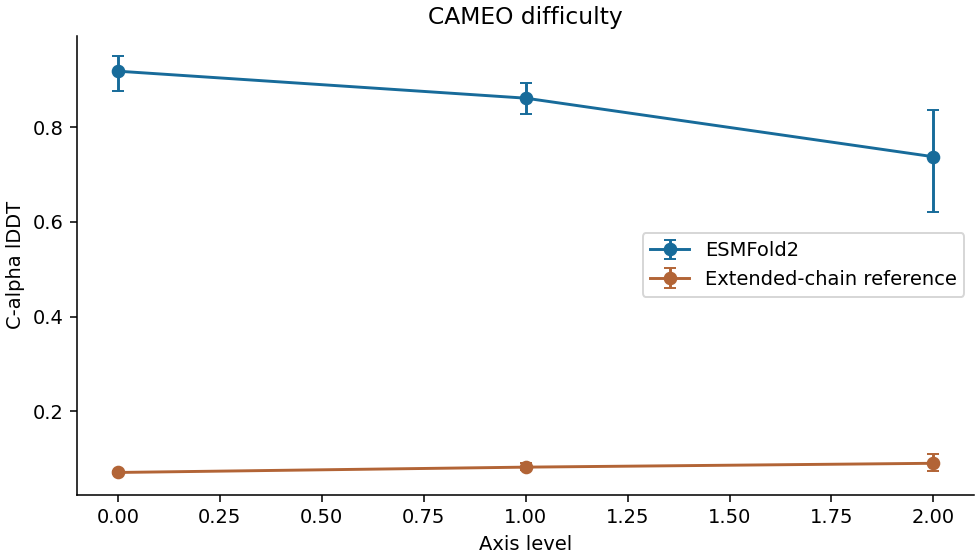

,level,n,ca_lddt_mean,ca_lddt_lo,ca_lddt_hi,baseline_ca_lddt_mean,baseline_ca_lddt_lo,baseline_ca_lddt_hi
0,0,28,0.832018,0.770704,0.887770,0.110103,0.096830,0.125844
1,1,27,0.814785,0.734593,0.885652,0.081648,0.076101,0.087169
2,2,28,0.888371,0.814116,0.944559,0.069777,0.066733,0.073264
3,3,27,0.916571,0.888620,0.939301,0.064969,0.062451,0.067758
4,4,28,0.908163,0.864053,0.943723,0.063856,0.061385,0.066396


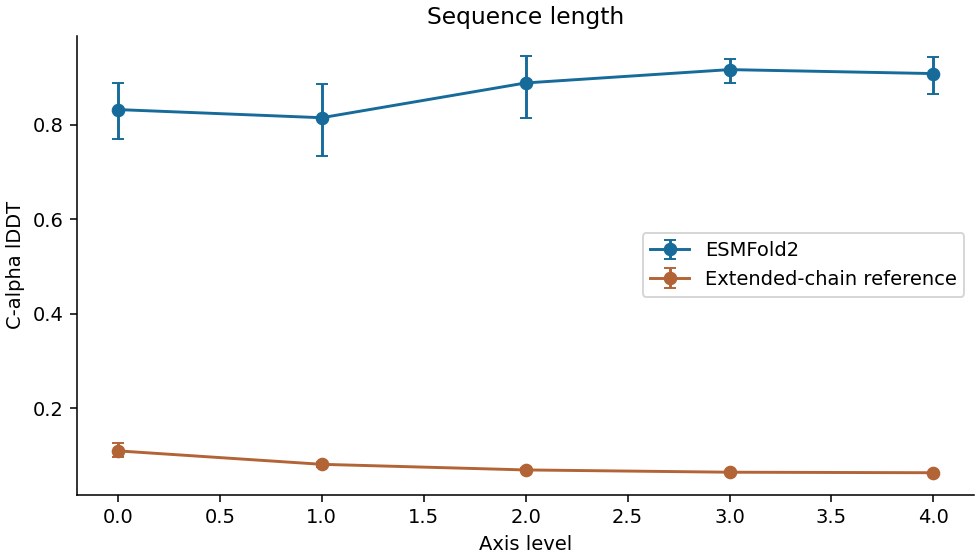

,feature,rho,p
0,difficulty,-0.473686,4.413658e-09
1,seq_len,0.318297,1.420501e-04
2,resolution,0.042735,6.187046e-01
3,msa_log10_nonquery_rows,0.379260,4.489275e-06


{'difficulty': {'xcols': ['difficulty',
   'msa_log10_nonquery_rows',
   'baseline_ca_lddt'],
  'coef': {'difficulty': -0.025189173614628916,
   'msa_log10_nonquery_rows': 0.048566834870684944,
   'baseline_ca_lddt': -1.7734674639805643},
  'intercept': 0.8745231357833609,
  'r2': 0.2527329686795474},
 'seq_len': {'xcols': ['seq_len',
   'msa_log10_nonquery_rows',
   'baseline_ca_lddt'],
  'coef': {'seq_len': -0.00012455001740056254,
   'msa_log10_nonquery_rows': 0.06169332057146423,
   'baseline_ca_lddt': -2.2924959515246024},
  'intercept': 0.8916625216358978,
  'r2': 0.2530139600801409},
 'resolution': {'xcols': ['resolution',
   'msa_log10_nonquery_rows',
   'baseline_ca_lddt'],
  'coef': {'resolution': 0.02848075347740634,
   'msa_log10_nonquery_rows': 0.05332118503308589,
   'baseline_ca_lddt': -1.799807386483108},
  'intercept': 0.7870091649127513,
  'r2': 0.25994083780244226}}

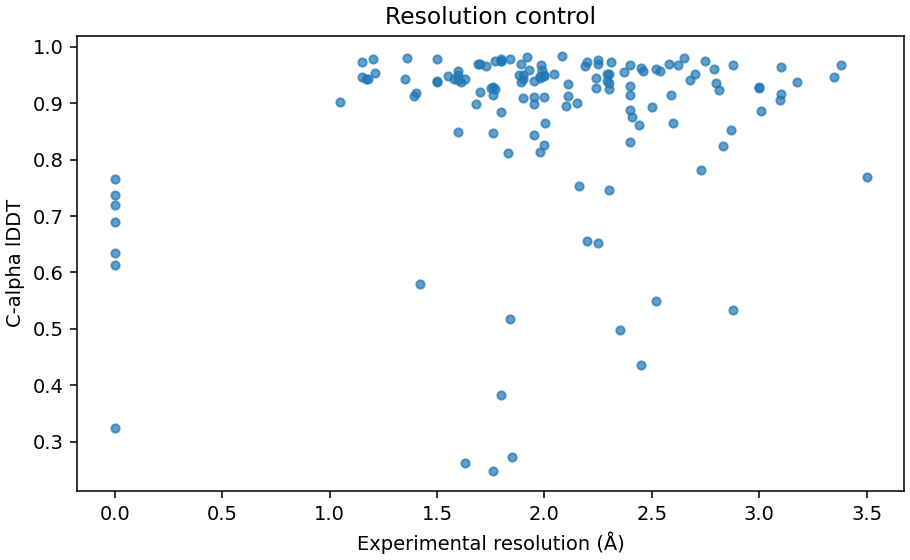

In [10]:
curves={}
for label,column in [('CAMEO difficulty','cameo_difficulty_level'),('Sequence length','length_q5_level')]:
    table=curve_intervals(measurements,column);curves[label]=table;display(table);plot_curve(table,label)
associations=pd.DataFrame([{'feature':name,'rho':stats.spearmanr(measurements[name],measurements.ca_lddt,nan_policy='omit').statistic,'p':stats.spearmanr(measurements[name],measurements.ca_lddt,nan_policy='omit').pvalue} for name in ['difficulty','seq_len','resolution','msa_log10_nonquery_rows']])
control_fits={name:linear_control(measurements,[name,'msa_log10_nonquery_rows','baseline_ca_lddt']) for name in ['difficulty','seq_len','resolution']}
display(associations);display(control_fits)
fig,ax=plt.subplots(figsize=(6.5,4),layout='constrained');ax.scatter(measurements.resolution,measurements.ca_lddt,s=18,alpha=.7);ax.set(xlabel='Experimental resolution (Å)',ylabel='C-alpha lDDT',title='Resolution control')
buffer=io.BytesIO();fig.savefig(buffer,format='png',dpi=140);plt.close(fig);display(Image(data=buffer.getvalue()))


## 6. What the agent decided, and why

Use the calculated direction, curve shape and controls below to state the result for this protein panel.


In [11]:
difficulty_curve=curves['CAMEO difficulty']
monotone=bool(np.all(np.diff(difficulty_curve.ca_lddt_mean)<0))
length_rho=float(associations.set_index('feature').loc['seq_len','rho'])
resolution_p=float(associations.set_index('feature').loc['resolution','p'])
decision=('Accept increasing CAMEO difficulty as a supported declining-accuracy regime.' if monotone else 'Reject a strictly monotone difficulty decline in this panel.')
print(decision)
print('Length:', 'the measured direction is opposite to a longer-chain decline.' if length_rho>=0 else 'accuracy decreases with length; inspect the adjusted fit above.')
print('Resolution:', 'no rank association at p<0.05.' if resolution_p>=.05 else 'a rank association is present; inspect direction and the adjusted fit above.')


Accept increasing CAMEO difficulty as a supported declining-accuracy regime.
Length: the measured direction is opposite to a longer-chain decline.
Resolution: no rank association at p<0.05.


In [12]:
output_dir=CALC_ROOT/f'axis-{AXIS_NUMBER:02}'
output_dir.mkdir(parents=True,exist_ok=True)
features.to_csv(output_dir/'input_features.csv',index=False)
axis_features.to_csv(output_dir/'axis_levels.csv',index=False)
measurements.to_csv(output_dir/'scored_targets.csv',index=False)
for name,table in curves.items():table.to_csv(output_dir/(re.sub(r'[^a-z0-9]+','_',name.lower())+'.csv'),index=False)
receipt={'analysis_id':f'esmfold2-featured/test-{AXIS_NUMBER:02}','completed':True,'source_files':raw_sources,'input_targets':len(features),'scored_targets':len(measurements),'decision':decision,'released_scores_sha256':sha256_file(score_source),'new_inference_executed':False,'calculation_scope':'raw source features, axis levels, released per-target measurement joins, curves and controls'}
(output_dir/'CALCULATION_RECEIPT.json').write_text(json.dumps(receipt,indent=2,default=str))


85917